In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from utils import (
    calculate_cost_basis_per_time,
    allocate_weekly_investment,
    get_decay_rate,
    compute_effective_annual_rate,
    compute_portfolio_effective_annual_return,
)

In [67]:
decay_rate = get_decay_rate(t1=90, t2=180, difference=0.05)
weekly_new_amount = 350
max_stock_buy = 80

In [68]:
# Read AAII.xlsx with header on row 1 (index 1)
aaii_df = pd.read_excel('AAII.xlsx', header=1)

In [69]:
# Read TransactionHistory.xlsx and merge in any new rows from the downloaded export
transactions_df = pd.read_excel('TransactionHistory.xlsx')

BASE_COLS = [
    'Activity/Trade Date',
    'Transaction Date',
    'Settlement Date',
    'Activity Type',
    'Description',
    'Symbol',
    'Cusip',
    'Quantity #',
    'Price $',
    'Amount $',
    'Commission',
    'Category',
    'Note',
]

def normalize_row_tuple(row):
    return tuple('' if pd.isna(v) else str(v).strip() for v in row)

raw_download = pd.read_excel('DownloadTxnHistory.xlsx')
header_idx = None
for i, row in raw_download.iterrows():
    if 'Activity/Trade Date' in [str(v).strip() for v in row.tolist() if pd.notna(v)]:
        header_idx = i
        break

if header_idx is not None:
    download_df = pd.read_excel('DownloadTxnHistory.xlsx', header=header_idx)
else:
    download_df = pd.read_excel('DownloadTxnHistory.xlsx', header=6)

if not download_df.empty and len(download_df.columns) > 0:
    date_like_mask = download_df.iloc[:, 0].astype(str).str.match(r'\d{1,2}/\d{1,2}/\d{4}', na=False)
    download_df = download_df.loc[date_like_mask].reset_index(drop=True)

if not download_df.empty:
    download_df.columns = BASE_COLS
    for col in ['Quantity #', 'Price $', 'Amount $', 'Commission']:
        download_df[col] = pd.to_numeric(download_df[col], errors='coerce')
    download_df = download_df[BASE_COLS].copy()

    transactions_keys = set(transactions_df.apply(normalize_row_tuple, axis=1))
    new_rows = download_df[~download_df.apply(normalize_row_tuple, axis=1).isin(transactions_keys)].copy()

    if not new_rows.empty:
        transactions_df = pd.concat([transactions_df, new_rows], ignore_index=True)
        transactions_df = transactions_df[BASE_COLS].copy()
        transactions_df.to_excel('TransactionHistory.xlsx', index=False)
        print(f'Added {len(new_rows)} new transaction rows to TransactionHistory.xlsx.')
    else:
        print('No new transactions to add from DownloadTxnHistory.xlsx.')
else:
    print('No transaction rows found in DownloadTxnHistory.xlsx.')

/home/rickshilling/shadowPortfolio/.venv/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/home/rickshilling/shadowPortfolio/.venv/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Added 11 new transaction rows to TransactionHistory.xlsx.


In [70]:
# Read deleted_shadow_stocks.txt
with open('deleted_shadow_stocks.txt', 'r') as f:
    deleted_stocks = [line.strip() for line in f if line.strip()]

# Get list of valid tickers from AAII (excluding deleted stocks)
valid_tickers = set(aaii_df['Ticker'].dropna().unique())
valid_tickers = valid_tickers - set(deleted_stocks)

# Filter transactions to only include stocks in AAII (and not deleted)
filtered_transactions = transactions_df[transactions_df['Symbol'].isin(valid_tickers)].copy()
filtered_transactions['Activity/Trade Date'] = pd.to_datetime(filtered_transactions['Activity/Trade Date'], format='mixed')
filtered_transactions = filtered_transactions.sort_values('Activity/Trade Date', ascending=False).reset_index(drop=True)

# Keep the filtered file aligned with the merged transaction history
filtered_transactions.to_excel('FilteredTransactionHistory.xlsx', index=False)
print(f'FilteredTransactionHistory.xlsx contains {len(filtered_transactions)} rows.')

FilteredTransactionHistory.xlsx contains 1738 rows.


In [71]:
# Convert date columns to datetime with mixed format handling
filtered_transactions['Activity/Trade Date'] = pd.to_datetime(filtered_transactions['Activity/Trade Date'], format='mixed')
filtered_transactions['Transaction Date'] = pd.to_datetime(filtered_transactions['Transaction Date'], format='mixed')
filtered_transactions['Settlement Date'] = pd.to_datetime(filtered_transactions['Settlement Date'], format='mixed')

# Parse activity type to identify buys and sells
print("Activity Type values:")
print(filtered_transactions['Activity Type'].value_counts())

Activity Type values:
Activity Type
Bought                998
0                     474
Dividend               87
Qualified Dividend     66
Stock Split             1
Name: count, dtype: int64


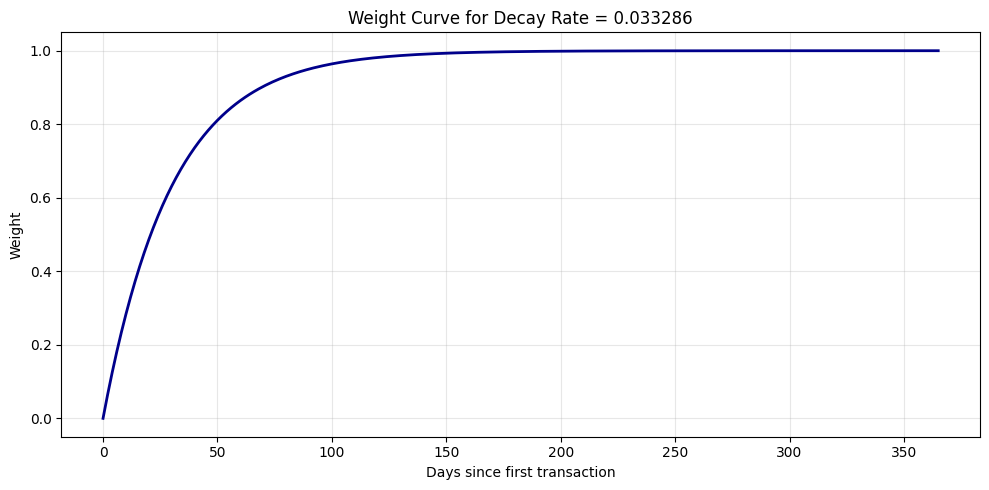

Cost basis per time:
   Ticker  Total Buy Cost  Total Sell Proceeds  Total Dividend Payout  \
0      NC         1922.66               184.41                  64.61   
1    CTRM         1501.51                 0.00                   0.00   
2     SND          871.46                 0.00                   0.00   
3     FRD         1678.70                 0.00                  14.73   
4    JRSH          898.40                 0.00                   0.00   
5    AMPY         1506.79                 0.00                   0.00   
6    GASS         1504.95                 0.00                   0.00   
7     EBF         1541.00                 0.00                 123.88   
8     RGS         1557.66                 0.00                   0.00   
9    ESCA         1502.45                 0.00                  71.16   
10   CMCO         1123.75                 0.00                   3.22   
11   PANL         1805.01               314.42                 168.29   
12   GILT         1490.64     

In [72]:
# Plot the decay weight curve for the chosen decay rate
days_since_first_transaction = np.arange(0, 366, 1)
weight_curve = 1 - np.exp(-decay_rate * days_since_first_transaction)

plt.figure(figsize=(10, 5))
plt.plot(days_since_first_transaction, weight_curve, color='darkblue', linewidth=2)
plt.xlabel('Days since first transaction')
plt.ylabel('Weight')
plt.title(f'Weight Curve for Decay Rate = {decay_rate:.6f}')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

reference_date = pd.Timestamp.now() + pd.Timedelta(days=7)  # 7 days from present
cost_basis_df = calculate_cost_basis_per_time(filtered_transactions, decay_rate=decay_rate, reference_date=reference_date)
print("Cost basis per time:")
print(cost_basis_df)
print("\nDividend payouts by stock:")
print(cost_basis_df[['Ticker', 'Total Dividend Payout']].sort_values('Total Dividend Payout', ascending=False))

allocation_df, updated_cost_basis_df = allocate_weekly_investment(cost_basis_df, aaii_df, weekly_new_amount, filtered_transactions, decay_rate=decay_rate, reference_date=reference_date, max_stock_buy=max_stock_buy)
print(f"Weekly investment allocation (${weekly_new_amount}) as of {reference_date.date()}:")
print(allocation_df)


Per-stock effective annual return:
   Ticker  Effective Annual Return
14   KGEI                 1.733457
4    JRSH                 1.371697
26     MG                 0.642918
3     FRD                 0.571580
15   RCKY                 0.405754
27   PKOH                 0.389509
11   PANL                 0.298584
24    OIS                 0.256703
13    EML                 0.225936
23   ESEA                 0.215147

Portfolio effective annual return: 16.516805%


/tmp/ipykernel_4744/2073240680.py:57: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


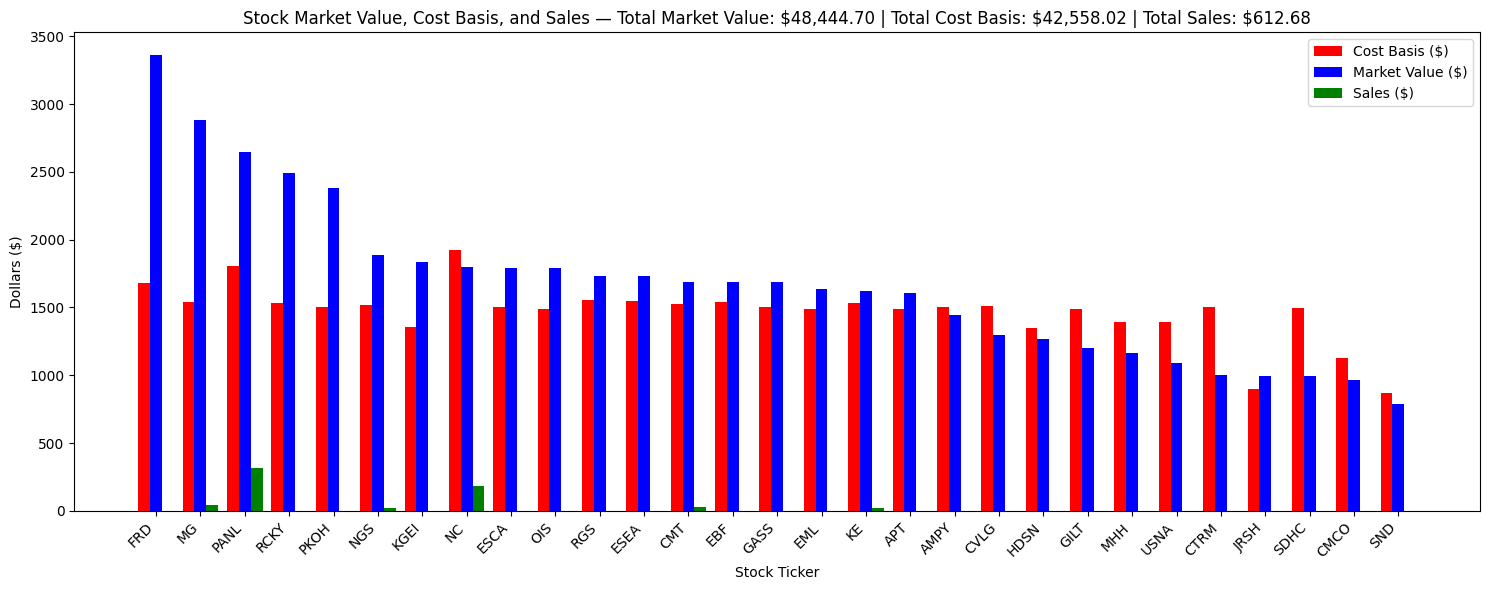

/tmp/ipykernel_4744/2073240680.py:87: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


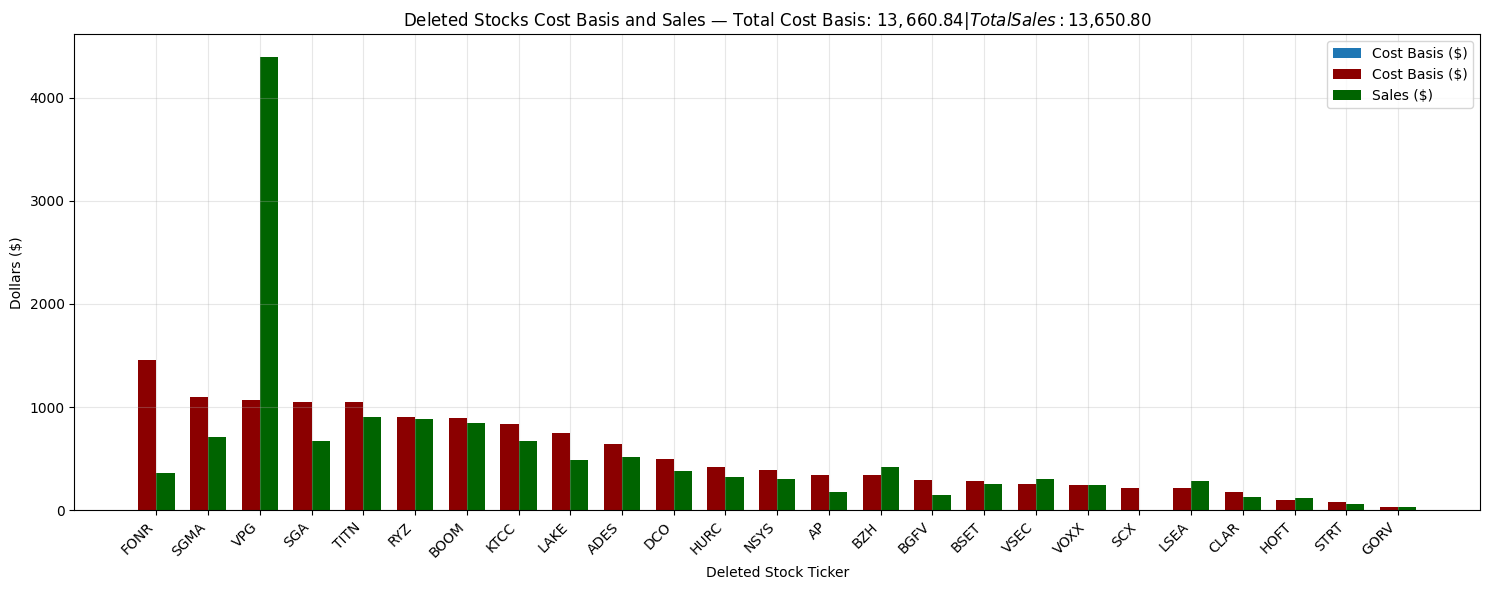

In [73]:
# Compute effective annual rate of return per stock and for the portfolio
stock_return_df = cost_basis_df.merge(
    aaii_df[['Ticker', 'CurrentPrice($)']],
    on='Ticker',
    how='left'
).copy()

stock_return_df['Market Value'] = stock_return_df['Total Shares'] * stock_return_df['CurrentPrice($)']
stock_return_df['Cost Basis'] = stock_return_df['Total Buy Cost']
stock_return_df['Sales'] = stock_return_df['Total Sell Proceeds']

stock_transactions = {ticker: group for ticker, group in filtered_transactions.groupby('Symbol')}
stock_return_df['Effective Annual Return'] = stock_return_df.apply(
    lambda row: compute_effective_annual_rate(
        stock_transactions.get(row['Ticker'], pd.DataFrame()).get('Amount $', pd.Series(dtype=float)).astype(float).to_numpy(),
        stock_transactions.get(row['Ticker'], pd.DataFrame()).get('Activity/Trade Date', pd.Series(dtype='datetime64[ns]')).tolist(),
        row['Market Value'],
        reference_date,
    ),
    axis=1,
)

portfolio_current_value = stock_return_df['Market Value'].sum()
portfolio_effective_annual_return = compute_portfolio_effective_annual_return(
    filtered_transactions,
    portfolio_current_value,
    reference_date,
)

print('Per-stock effective annual return:')
print(stock_return_df[['Ticker', 'Effective Annual Return']].sort_values('Effective Annual Return', ascending=False).head(10))
print(f'\nPortfolio effective annual return: {portfolio_effective_annual_return:.6%}')

# Plot market value, cost basis, and sales by stock
plot_df = stock_return_df.copy()
plot_df = plot_df.sort_values('Market Value', ascending=False).reset_index(drop=True)

x = np.arange(len(plot_df))
bar_width = 0.8 / 3

fig, ax = plt.subplots(figsize=(15, 6), layout='constrained')
ax.bar(x - bar_width, plot_df['Cost Basis'], width=bar_width, color='r', label='Cost Basis ($)')
ax.bar(x, plot_df['Market Value'], width=bar_width, color='b', label='Market Value ($)')
ax.bar(x + bar_width, plot_df['Sales'], width=bar_width, color='g', label='Sales ($)')

ax.set_xticks(x)
ax.set_xticklabels(plot_df['Ticker'], rotation=45, ha='right')
ax.set_ylabel('Dollars ($)')
ax.set_xlabel('Stock Ticker')
ax.set_title(
    f"Stock Market Value, Cost Basis, and Sales — "
    f"Total Market Value: ${plot_df['Market Value'].sum():,.2f} | "
    f"Total Cost Basis: ${plot_df['Cost Basis'].sum():,.2f} | "
    f"Total Sales: ${plot_df['Sales'].sum():,.2f}"
)
ax.legend()
plt.tight_layout()
plt.show()

# Plot deleted-stock cost basis and sales separately
if deleted_stocks:
    deleted_transactions = transactions_df[transactions_df['Symbol'].isin(deleted_stocks)].copy()
    deleted_transactions['Activity/Trade Date'] = pd.to_datetime(deleted_transactions['Activity/Trade Date'], format='mixed')
    deleted_cost_basis_df = calculate_cost_basis_per_time(deleted_transactions, decay_rate=decay_rate, reference_date=reference_date)
    deleted_cost_basis_df = deleted_cost_basis_df[['Ticker', 'Total Buy Cost', 'Total Sell Proceeds']].copy()
    deleted_cost_basis_df = deleted_cost_basis_df.sort_values(['Total Buy Cost', 'Total Sell Proceeds'], ascending=[False, False]).reset_index(drop=True)

    if not deleted_cost_basis_df.empty:
        deleted_x = np.arange(len(deleted_cost_basis_df))
        deleted_bar_width = 0.35

        fig, ax = plt.subplots(figsize=(15, 6), layout='constrained')
        ax.bar(deleted_x - deleted_bar_width / 2, deleted_cost_basis_df['Total Buy Cost'], width=deleted_bar_width, color=plt.get_cmap('tab20')(0), label='Cost Basis ($)')
        ax.bar(deleted_x - deleted_bar_width / 2, deleted_cost_basis_df['Total Buy Cost'], width=deleted_bar_width, color='darkred', label='Cost Basis ($)')
        ax.bar(deleted_x + deleted_bar_width / 2, deleted_cost_basis_df['Total Sell Proceeds'], width=deleted_bar_width, color='darkgreen', label='Sales ($)')
        ax.set_xticks(deleted_x)
        ax.set_xticklabels(deleted_cost_basis_df['Ticker'], rotation=45, ha='right')
        ax.set_ylabel('Dollars ($)')
        ax.set_xlabel('Deleted Stock Ticker')
        ax.set_title(
            f"Deleted Stocks Cost Basis and Sales — "
            f"Total Cost Basis: ${deleted_cost_basis_df['Total Buy Cost'].sum():,.2f} | "
            f"Total Sales: ${deleted_cost_basis_df['Total Sell Proceeds'].sum():,.2f}"
        )
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    else:
        print('No deleted-stock transaction data available for plotting.')
else:
    print('No deleted stocks in the list to plot.')

/tmp/ipykernel_4744/135432926.py:52: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


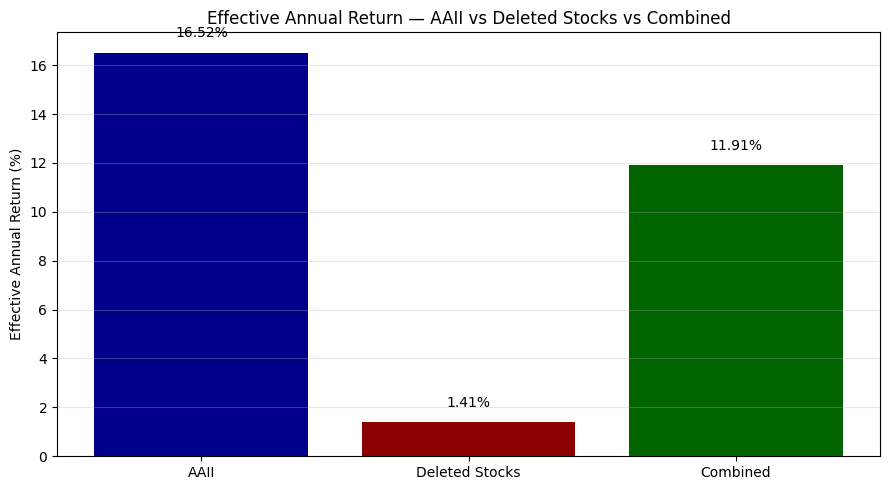

In [74]:
# Compare effective annual return for the active AAII portfolio, deleted-stock portfolio, and combined portfolio
aaii_market_value = stock_return_df['Market Value'].sum()
aaii_effective_return = compute_portfolio_effective_annual_return(
    filtered_transactions,
    aaii_market_value,
    reference_date,
)

deleted_transactions = transactions_df[transactions_df['Symbol'].isin(deleted_stocks)].copy()
deleted_transactions['Activity/Trade Date'] = pd.to_datetime(deleted_transactions['Activity/Trade Date'], format='mixed')
deleted_current_value = 0.0

if not deleted_transactions.empty:
    for ticker, group in deleted_transactions.groupby('Symbol'):
        group = group.sort_values('Activity/Trade Date').copy()
        last_row = group.dropna(subset=['Quantity #', 'Price $']).tail(1)
        if last_row.empty:
            continue
        qty = pd.to_numeric(last_row['Quantity #'].iloc[0], errors='coerce')
        price = pd.to_numeric(last_row['Price $'].iloc[0], errors='coerce')
        if pd.notna(qty) and pd.notna(price) and qty > 0:
            deleted_current_value += qty * price
    deleted_effective_return = compute_portfolio_effective_annual_return(
        deleted_transactions,
        deleted_current_value,
        reference_date,
    )
else:
    deleted_effective_return = np.nan

combined_current_value = aaii_market_value + deleted_current_value
combined_transactions = pd.concat([filtered_transactions, deleted_transactions], ignore_index=True)
combined_effective_return = compute_portfolio_effective_annual_return(
    combined_transactions,
    combined_current_value,
    reference_date,
)

comparison_df = pd.DataFrame({
    'Portfolio': ['AAII', 'Deleted Stocks', 'Combined'],
    'Effective Annual Return': [aaii_effective_return, deleted_effective_return, combined_effective_return],
})

fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
ax.bar(comparison_df['Portfolio'], comparison_df['Effective Annual Return'] * 100, color=['darkblue', 'darkred', 'darkgreen'])
ax.set_ylabel('Effective Annual Return (%)')
ax.set_title('Effective Annual Return — AAII vs Deleted Stocks vs Combined')
ax.grid(True, axis='y', alpha=0.3)
for bar, value in zip(ax.patches, comparison_df['Effective Annual Return'] * 100):
    if pd.notna(value):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.5, f'{value:.2f}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()


/tmp/ipykernel_4744/2208390292.py:12: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


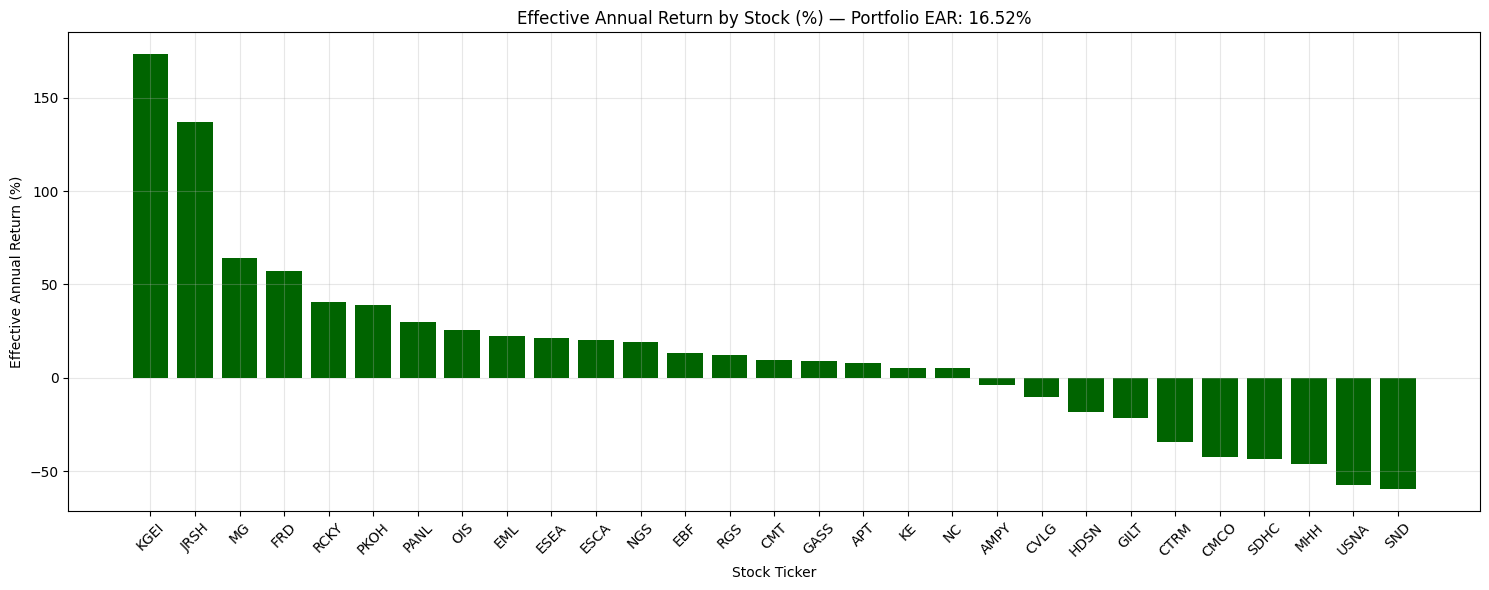

In [75]:
# Plot effective annual return by stock in percent
annual_return_plot_df = stock_return_df[['Ticker', 'Effective Annual Return']].copy()
annual_return_plot_df = annual_return_plot_df.sort_values('Effective Annual Return', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(15, 6), layout='constrained')
ax.bar(annual_return_plot_df['Ticker'], annual_return_plot_df['Effective Annual Return'] * 100, color='darkgreen')
ax.set_ylabel('Effective Annual Return (%)')
ax.set_xlabel('Stock Ticker')
ax.set_title(f'Effective Annual Return by Stock (%) — Portfolio EAR: {portfolio_effective_annual_return:.2%}')
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


/tmp/ipykernel_4744/3854671482.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


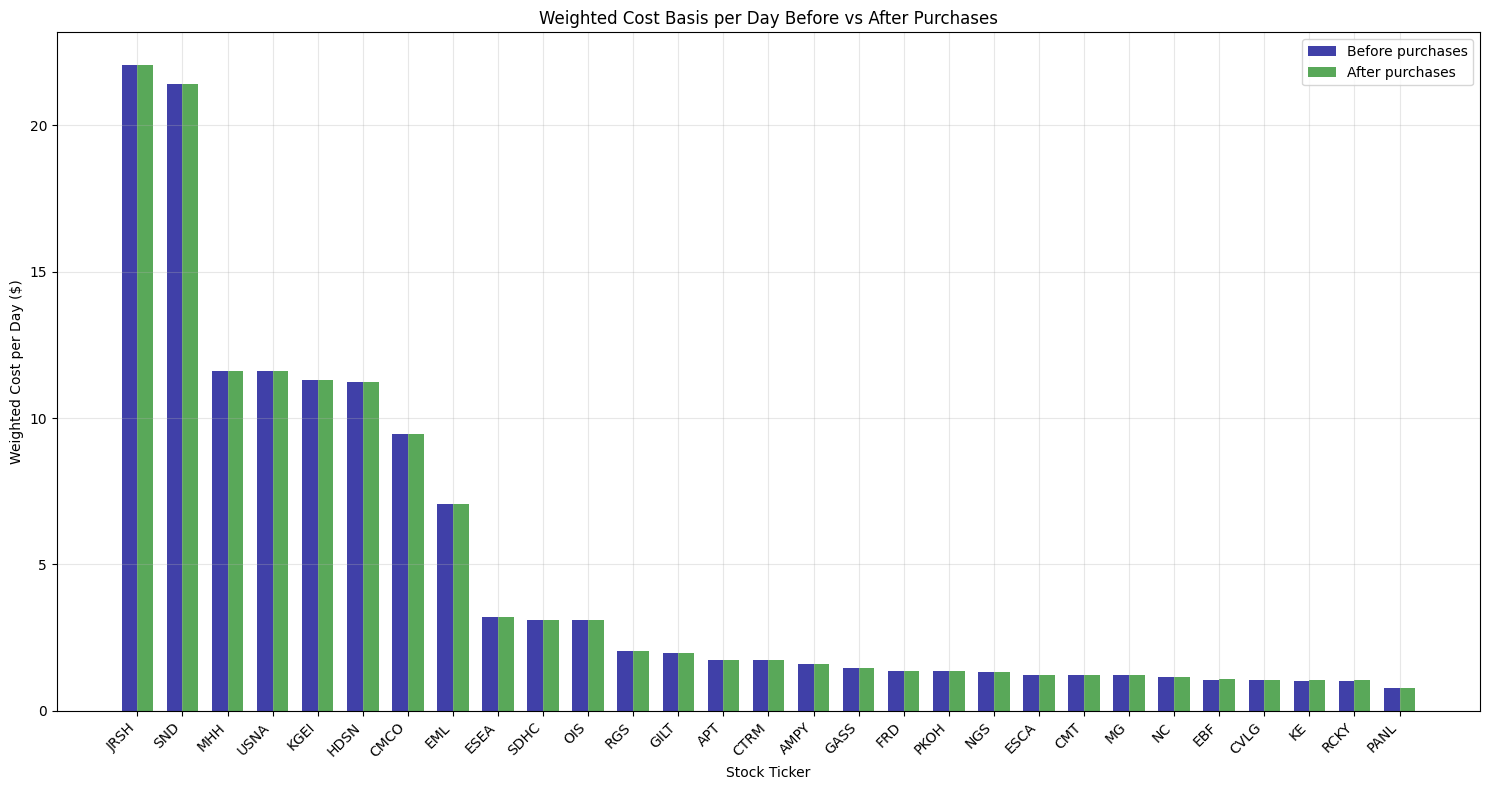

In [78]:
# Plot weighted cost per day before and after purchases on the same chart
base_weight_df = cost_basis_df[['Ticker', 'Weighted Cost per Day']].rename(columns={'Weighted Cost per Day': 'Weighted Cost per Day (Before)'}).copy()
updated_weight_df = updated_cost_basis_df[['Ticker', 'Weighted Cost per Day']].rename(columns={'Weighted Cost per Day': 'Weighted Cost per Day (After)'}).copy()
plot_df4 = base_weight_df.merge(updated_weight_df, on='Ticker', how='outer').fillna(0)
plot_df4 = plot_df4.sort_values(['Weighted Cost per Day (After)', 'Weighted Cost per Day (Before)'], ascending=[False, False]).reset_index(drop=True)

x = np.arange(len(plot_df4))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(15, 8), layout='constrained')
ax.bar(x - bar_width/2, plot_df4['Weighted Cost per Day (Before)'], width=bar_width, color='darkblue', alpha=0.75, label='Before purchases')
ax.bar(x + bar_width/2, plot_df4['Weighted Cost per Day (After)'], width=bar_width, color='forestgreen', alpha=0.75, label='After purchases')

ax.set_xticks(x)
ax.set_xticklabels(plot_df4['Ticker'], rotation=45, ha='right')
ax.set_ylabel('Weighted Cost per Day ($)')
ax.set_xlabel('Stock Ticker')
ax.set_title('Weighted Cost Basis per Day Before vs After Purchases')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


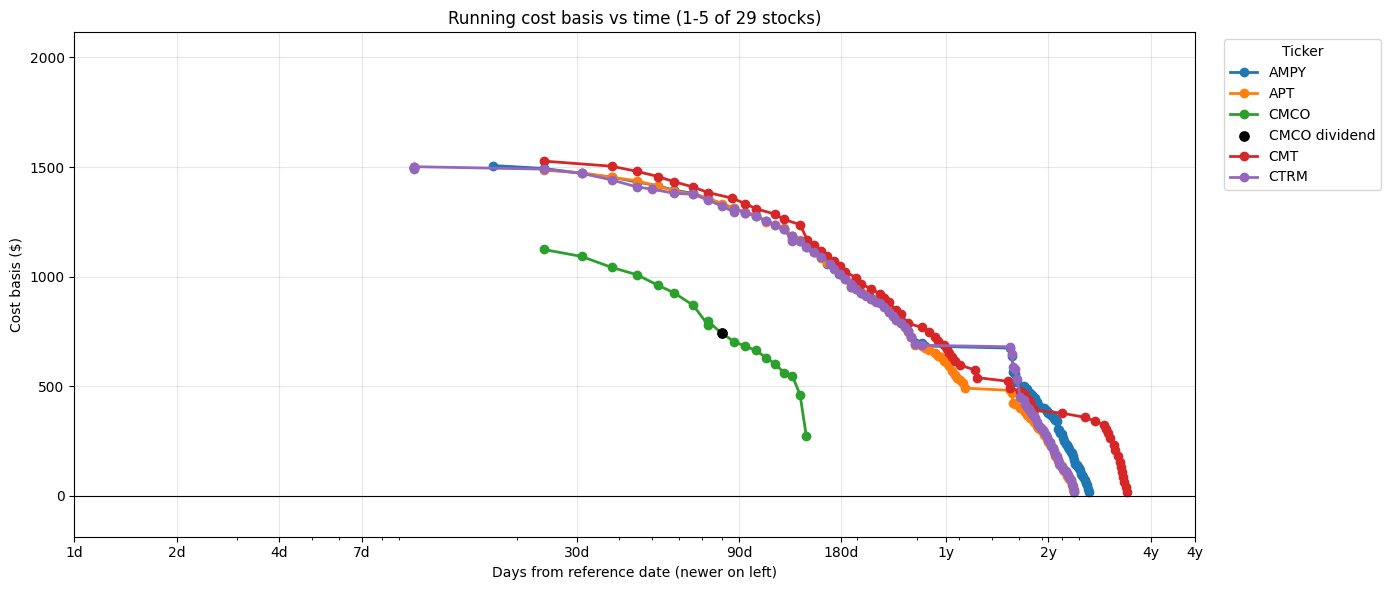

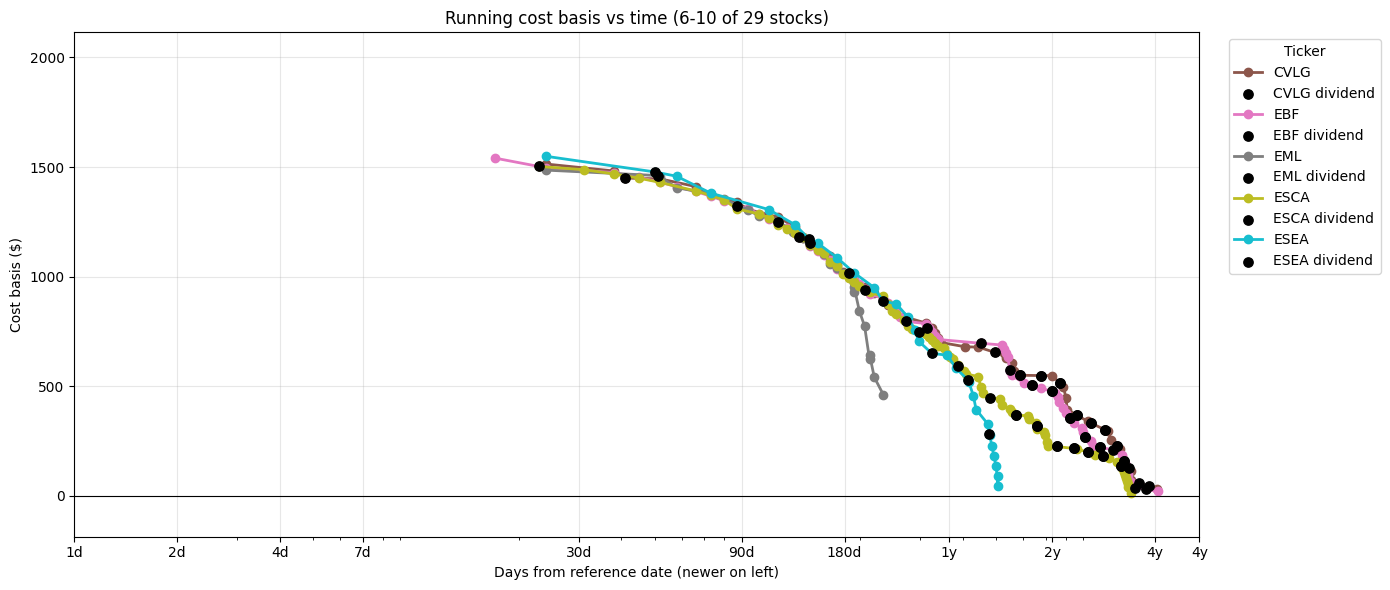

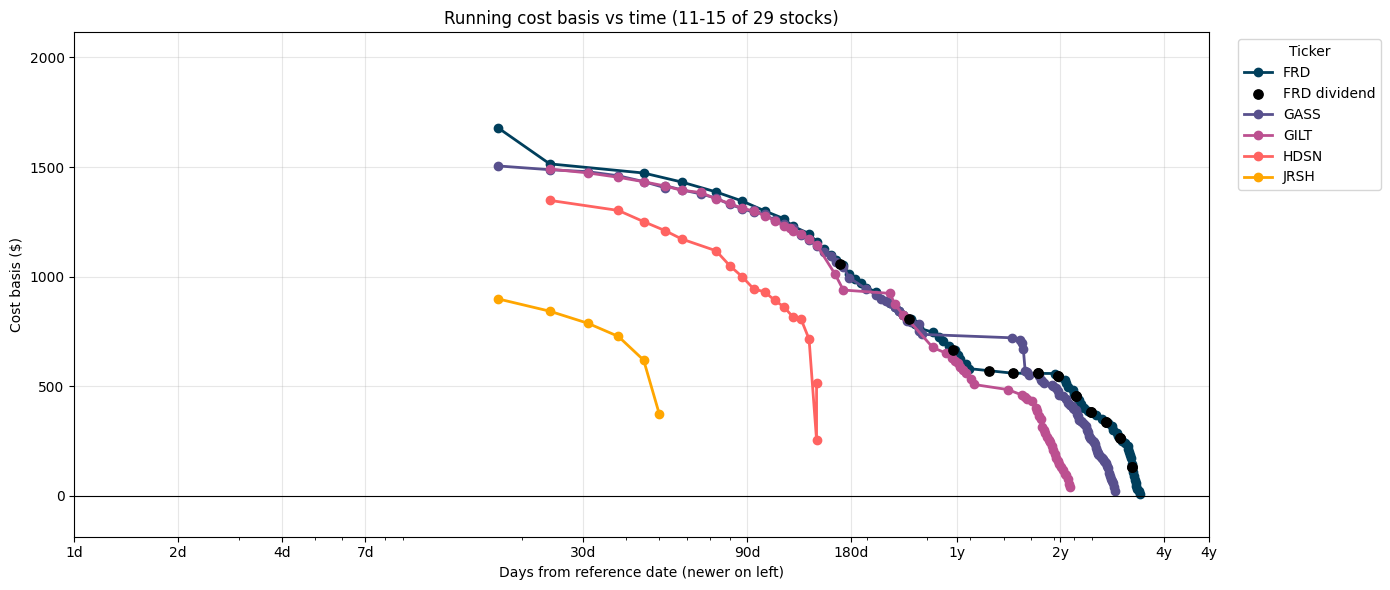

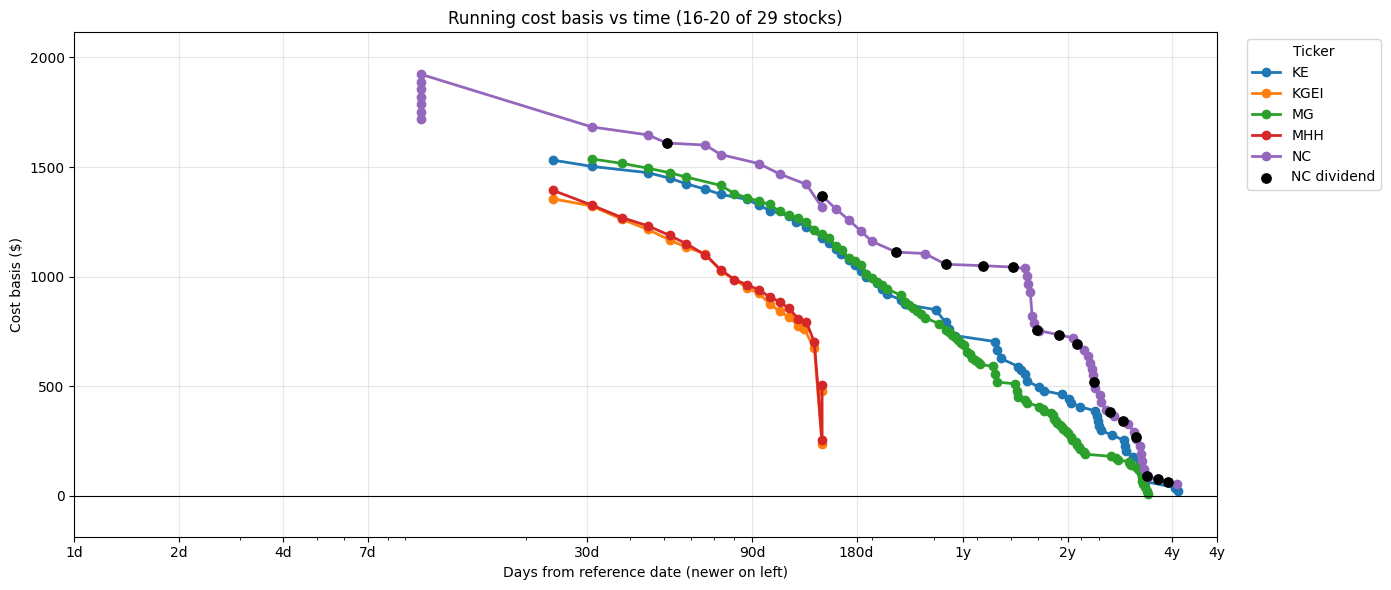

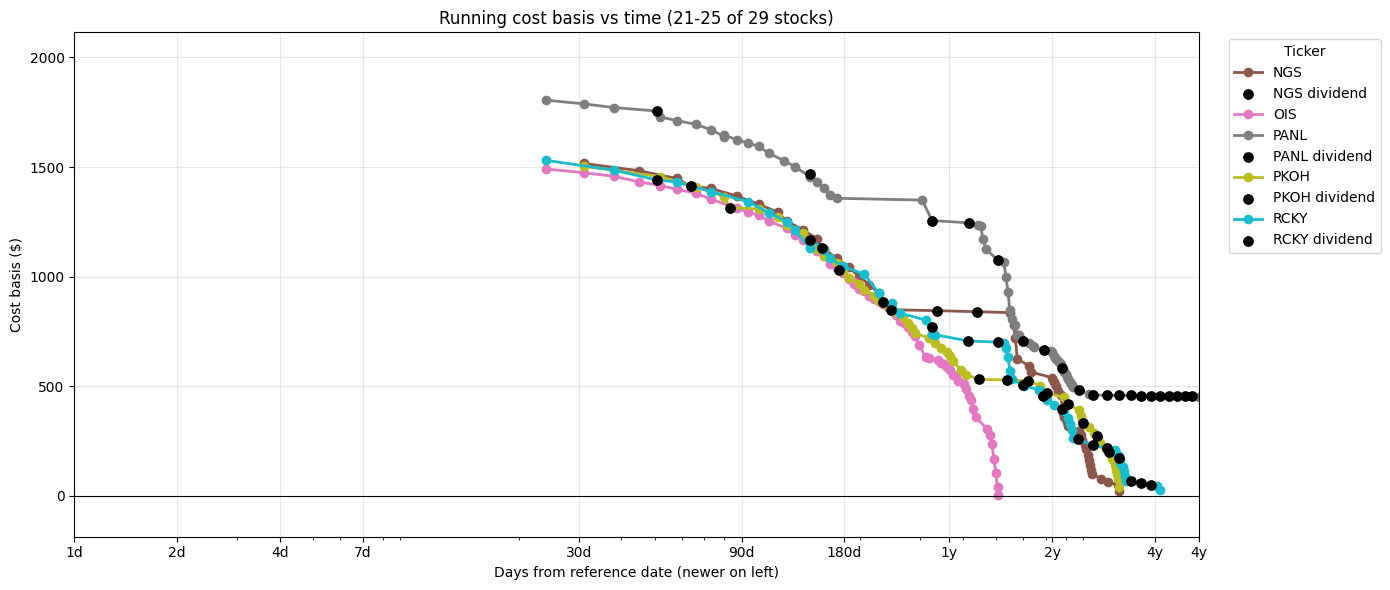

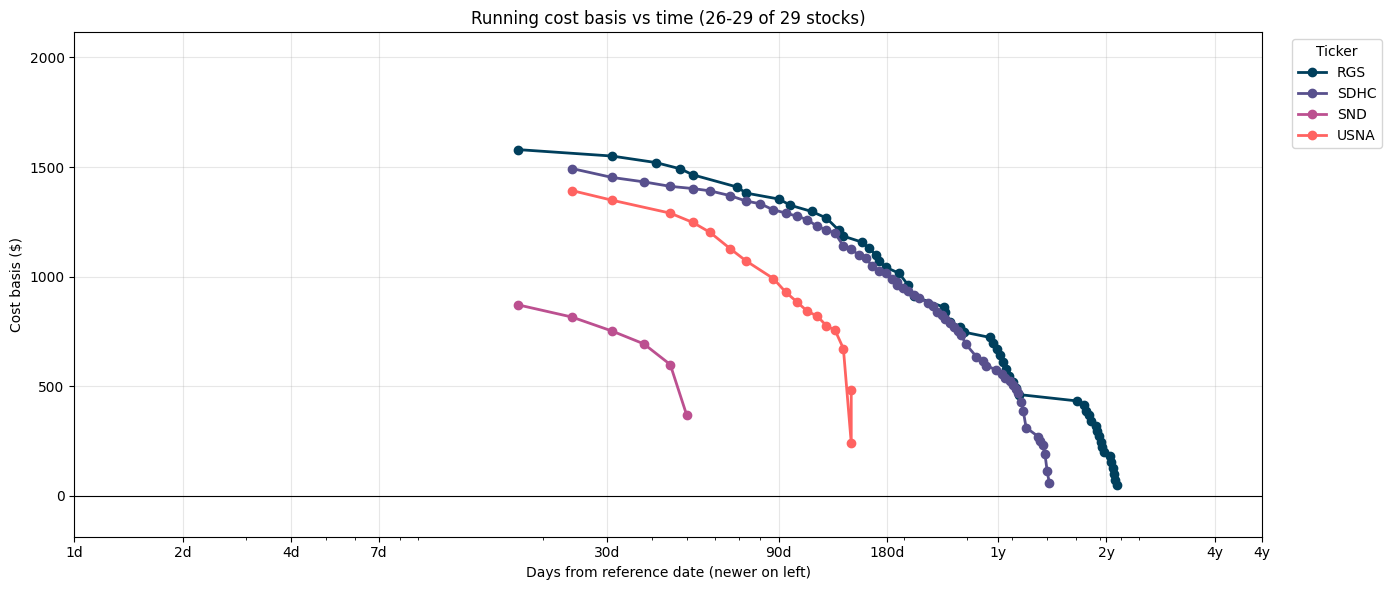

In [ ]:
# Plot running cost basis vs time relative to the reference date
# Show 5 stocks per chart, with newer transactions on the left.
cash_flow_df = filtered_transactions[["Symbol", "Activity/Trade Date", "Amount $", "Quantity #"]].copy()
cash_flow_df["Amount $"] = pd.to_numeric(cash_flow_df["Amount $"], errors="coerce")
cash_flow_df["Quantity #"] = pd.to_numeric(cash_flow_df["Quantity #"], errors="coerce")
cash_flow_df = cash_flow_df.dropna(subset=["Amount $"]).copy()


def classify_cash_flow(row):
    amount = row["Amount $"]
    quantity = row["Quantity #"]

    if pd.isna(amount):
        return None
    if amount < 0:
        return "buy"
    if amount > 0:
        if pd.isna(quantity) or quantity == 0:
            return "dividend"
        if quantity < 0:
            return "sell"
    return None


cash_flow_df["Flow Type"] = cash_flow_df.apply(classify_cash_flow, axis=1)
cash_flow_df = cash_flow_df[cash_flow_df["Flow Type"].notna()].copy()

# Cost basis only accumulates purchases; dividends are shown separately.
cash_flow_df["Basis Impact"] = 0.0
cash_flow_df.loc[cash_flow_df["Flow Type"] == "buy", "Basis Impact"] = cash_flow_df.loc[cash_flow_df["Flow Type"] == "buy", "Amount $"].abs()

all_cost_basis_values = []
all_days_from_reference = []
stock_plot_data = []
for ticker, group in cash_flow_df.groupby("Symbol"):
    plot_df = group.sort_values("Activity/Trade Date").copy()
    buy_df = plot_df[plot_df["Flow Type"] == "buy"].copy()
    dividend_df = plot_df[plot_df["Flow Type"] == "dividend"].copy()
    if buy_df.empty:
        continue
    buy_df["Cumulative Cost Basis"] = buy_df["Basis Impact"].cumsum()
    buy_df["Days from reference"] = (reference_date - buy_df["Activity/Trade Date"]).dt.days.abs().clip(lower=1)
    buy_df = buy_df.sort_values(["Days from reference", "Activity/Trade Date"], ascending=[True, True]).reset_index(drop=True)
    all_cost_basis_values.append(buy_df["Cumulative Cost Basis"].to_numpy())
    all_days_from_reference.append(buy_df["Days from reference"].to_numpy())
    stock_plot_data.append((ticker, buy_df, dividend_df))

common_y_limits = None
common_x_limits = None
if all_cost_basis_values:
    flat_values = np.concatenate(all_cost_basis_values)
    y_min = float(np.min(flat_values))
    y_max = float(np.max(flat_values))
    y_padding = max((y_max - y_min) * 0.10, 1.0)
    common_y_limits = (y_min - y_padding, y_max + y_padding)

shared_tick_values = np.array([1.0, 2.0, 4.0, 7.0, 30.0, 90.0, 180.0, 365.0, 730.0, 1460.0], dtype=float)
if all_days_from_reference:
    flat_days = np.concatenate(all_days_from_reference)
    x_min = float(np.min(flat_days))
    x_max = float(np.max(flat_days))
    common_x_limits = (x_min, x_max)
    shared_tick_values = np.unique(np.concatenate([shared_tick_values, np.array([x_max], dtype=float)]))

running_cost_basis_palette = [
    '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
    '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf',
    '#003f5c', '#58508d', '#bc5090', '#ff6361', '#ffa600'
]

for batch_start in range(0, len(stock_plot_data), 5):
    batch = stock_plot_data[batch_start:batch_start + 5]
    fig, ax = plt.subplots(figsize=(14, 6))

    for idx, (ticker, buy_df, dividend_df) in enumerate(batch):
        x_values = buy_df["Days from reference"].to_numpy(dtype=float)
        color = running_cost_basis_palette[idx % len(running_cost_basis_palette)]
        ax.plot(
            x_values,
            buy_df["Cumulative Cost Basis"],
            color=color,
            linewidth=2,
            marker="o",
            label=ticker,
        )
        if not dividend_df.empty:
            dividend_df = dividend_df.sort_values("Activity/Trade Date", ascending=True).copy()
            dividend_days = (reference_date - dividend_df["Activity/Trade Date"]).dt.days.abs().clip(lower=1)
            dividend_y = np.interp(
                dividend_days.to_numpy(dtype=float),
                x_values,
                buy_df["Cumulative Cost Basis"].to_numpy(dtype=float),
                left=buy_df["Cumulative Cost Basis"].iloc[0],
                right=buy_df["Cumulative Cost Basis"].iloc[-1],
            )
            ax.scatter(
                dividend_days.to_numpy(dtype=float),
                dividend_y,
                color="black",
                s=45,
                label=f"{ticker} dividend",
                zorder=5,
            )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"Running cost basis vs time ({batch_start + 1}-{min(batch_start + 5, len(stock_plot_data))} of {len(stock_plot_data)} stocks)")
    ax.set_xlabel("Days from reference date (newer on left)")
    ax.set_ylabel("Cost basis ($)")
    ax.grid(True, alpha=0.3)
    ax.set_xscale("log")
    if common_x_limits is not None:
        ax.set_xlim(common_x_limits[1], common_x_limits[0])
        ax.invert_xaxis()
    if common_y_limits is not None:
        ax.set_ylim(common_y_limits)
    ax.set_xticks(shared_tick_values)
    ax.set_xticklabels([
        "1d" if v == 1.0 else
        "2d" if v == 2.0 else
        "4d" if v == 4.0 else
        "7d" if v == 7.0 else
        "30d" if v == 30.0 else
        "90d" if v == 90.0 else
        "180d" if v == 180.0 else
        "1y" if v >= 365.0 and v < 730.0 else
        "2y" if v >= 730.0 and v < 1460.0 else
        "4y" if v >= 1460.0 else
        f"{int(v)}d"
        for v in shared_tick_values
    ])
    ax.legend(title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
